1. Import Libraries:
Import necessary libraries for numerical operations, data manipulation, plotting, and data splitting

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split


2. Load and Inspect Dataset:
Load the temperature dataset from CSV, inspect its dimensions, column names, missing value counts, and preview the first few rows

In [3]:
df = pd.read_csv(r"C:\Users\cheta\Desktop\ML Projects\Linear regression\ev_dataset\EV_Range_Prediction_Dataset_2000.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

df.head()

Dataset shape: (2000, 17)

Columns:
['timestamp', 'battery_soc', 'voltage', 'current', 'power_consumption', 'speed', 'distance_traveled', 'road_gradient', 'traffic_density', 'temperature', 'humidity', 'wind_speed', 'driving_style', 'vehicle_load', 'battery_health', 'regen_braking', 'remaining_range']

Missing values:
timestamp            0
battery_soc          0
voltage              0
current              0
power_consumption    0
speed                0
distance_traveled    0
road_gradient        0
traffic_density      0
temperature          0
humidity             0
wind_speed           0
driving_style        0
vehicle_load         0
battery_health       0
regen_braking        0
remaining_range      0
dtype: int64


,timestamp,battery_soc,voltage,current,power_consumption,speed,distance_traveled,road_gradient,traffic_density,temperature,humidity,wind_speed,driving_style,vehicle_load,battery_health,regen_braking,remaining_range
0,2024-01-01 00:00:00,43.71,331.40,118.68,16.91,89.23,1.93,3.51,Medium,28.98,43.05,4.86,Eco,139.30,88.75,2.15,60.65
1,2024-01-01 00:01:00,95.56,329.64,163.03,5.96,85.60,1.73,-3.96,Medium,24.77,45.84,10.08,Normal,172.49,96.55,37.11,262.33
2,2024-01-01 00:02:00,75.88,408.75,154.43,22.07,20.53,0.96,-1.85,High,37.97,74.96,16.35,Eco,130.87,75.85,43.99,150.66
3,2024-01-01 00:03:00,63.88,329.95,39.24,16.10,111.48,3.08,5.06,High,15.49,40.67,7.60,Eco,395.16,91.94,21.26,120.57
4,2024-01-01 00:04:00,24.04,332.63,38.36,5.62,72.53,2.44,1.87,High,27.96,44.75,2.68,Aggressive,103.43,78.12,20.68,6.06


3. Data Validation and Feature/Target Separation :
Validate that the target column (`remaining_range`) exists and ensure there are no missing values before extracting features ($X$) and target ($y$).

In [4]:
target_col = "remaining_range"

if target_col not in df.columns:
    raise ValueError(f"The dataset must contain a '{target_col}' column.")

if df.isnull().any().any():
    raise ValueError("The dataset contains missing values. Handle them before training.")

# Drop the target column as well as non-numeric/categorical columns before converting to float
X = df.drop(columns=[target_col, "timestamp", "traffic_density", "driving_style"]).to_numpy(dtype=float)
y = df[target_col].to_numpy(dtype=float).reshape(-1, 1)

print("Features:", X.shape)
print("Target:", y.shape)

Features: (2000, 13)
Target: (2000, 1)


4. Train-Validation-Test Split:
Split data into training, validation, and test subsets to allow unbiased model evaluation and hyperparameter tuning.

In [5]:

# First, reserve 20% for the final test
X_train_val, X_test_raw, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# From the remaining 80%, reserve 20% for validation
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.20, random_state=42
)

print("Training samples:", len(y_train))
print("Validation samples:", len(y_val))
print("Test samples:", len(y_test))


Training samples: 1280
Validation samples: 320
Test samples: 400


5. Feature Normalization (Scaling) :
Define custom feature scaling functions to compute means and standard deviations from training data and apply transformations across all sets.

In [6]:

def Normalize_Fit(X):
    mean = np.mean(X, axis=0)
    std = np.std(X, axis=0)

    # Prevent division by zero for constant features
    std[std == 0] = 1

    return mean, std


def Normalize_Transform(X, mean, std):
    return (X - mean) / std


X_mean, X_std = Normalize_Fit(X_train_raw)

X_train_scaled = Normalize_Transform(X_train_raw, X_mean, X_std)
X_val_scaled = Normalize_Transform(X_val_raw, X_mean, X_std)
X_test_scaled = Normalize_Transform(X_test_raw, X_mean, X_std)

print("Training feature means (first 5):",
      X_train_scaled.mean(axis=0)[:5])

print("Training feature stds (first 5):",
      X_train_scaled.std(axis=0)[:5])


Training feature means (first 5): [1.41865686e-15 1.17069548e-14 1.75380543e-15 2.33060099e-15
 3.09331553e-15]
Training feature stds (first 5): [1. 1. 1. 1. 1.]


6. Add Bias Term:
Append a column of ones to the feature matrices to account for the model intercept during matrix operations.

In [7]:

def Add_Bias(X):
    return np.c_[np.ones((X.shape[0], 1)), X]


X_train = Add_Bias(X_train_scaled)
X_val = Add_Bias(X_val_scaled)
X_test = Add_Bias(X_test_scaled)

print("Training matrix:", X_train.shape)
print("Validation matrix:", X_val.shape)
print("Test matrix:", X_test.shape)


Training matrix: (1280, 14)
Validation matrix: (320, 14)
Test matrix: (400, 14)


7. Define Prediction and Loss Functions:
Implement helper functions for linear hypothesis prediction, performance metrics (MSE, MAE, RMSE, NRMSE), and regularized objective functions (L1/L2 penalties).

In [8]:

def Prediction(X, w):
    return X @ w


def MSE_Loss(t, y_pred):
    return np.mean((t - y_pred) ** 2)


def MAE_Loss(t, y_pred):
    return np.mean(np.abs(t - y_pred))


def RMSE_Loss(t, y_pred):
    return np.sqrt(MSE_Loss(t, y_pred))


def L1_Loss(X, t, w, lambda_):
    y_pred = Prediction(X, w)
    penalty = np.sum(np.abs(w[1:]))
    return MSE_Loss(t, y_pred) + lambda_ * penalty


def L2_Loss(X, t, w, lambda_):
    y_pred = Prediction(X, w)
    penalty = np.sum(w[1:] ** 2)
    return MSE_Loss(t, y_pred) + lambda_ * penalty


def NRMSE(t, y_pred):
    target_range = np.max(t) - np.min(t)

    if target_range == 0:
        return np.nan

    return RMSE_Loss(t, y_pred) / target_range


8. Define Loss Gradients:
Implement analytical gradient functions for MSE, MAE, RMSE, and regularized loss objectives (L1/L2 penalties).

In [9]:

def MSE_Gradient(X, t, w):
    error = Prediction(X, w) - t
    return (2 / len(t)) * (X.T @ error)


def MAE_Gradient(X, t, w):
    error = Prediction(X, w) - t
    return (X.T @ np.sign(error)) / len(t)


def RMSE_Gradient(X, t, w):
    rmse = RMSE_Loss(t, Prediction(X, w))

    if rmse == 0:
        return np.zeros_like(w)

    return MSE_Gradient(X, t, w) / (2 * rmse)


def L1_Gradient(X, t, w, lambda_):
    penalty_gradient = np.sign(w)
    penalty_gradient[0] = 0

    return MSE_Gradient(X, t, w) + lambda_ * penalty_gradient


def L2_Gradient(X, t, w, lambda_):
    penalty_gradient = np.zeros_like(w)
    penalty_gradient[1:] = 2 * w[1:]

    return MSE_Gradient(X, t, w) + lambda_ * penalty_gradient


9. Implement Gradient Descent Optimization:
Define the iterative gradient descent optimization routine utilizing L2 regularization and convergence tolerance checks.

In [10]:

def Gradient_Descent(
    X, X_val, t, t_val, w, lambda_,
    max_iter, learning_rate, tolerance
):
    loss_history = []

    for iteration in range(max_iter):
        gradient = L2_Gradient(X, t, w, lambda_)
        w = w - learning_rate * gradient

        train_objective = L2_Loss(X, t, w, lambda_)
        loss_history.append(train_objective)

        # Stop if the gradient is sufficiently small
        if np.linalg.norm(gradient) < tolerance:
            break

    train_loss = L2_Loss(X, t, w, lambda_)
    val_loss = L2_Loss(X_val, t_val, w, lambda_)

    y_val_pred = Prediction(X_val, w)
    val_nrmse = NRMSE(t_val, y_val_pred)

    return w, train_loss, val_loss, val_nrmse, loss_history


10. Train Model via Gradient Descent :
Configure hyperparameters (learning rate, regularization lambda, iterations, tolerance), initialize weights, and run the optimization process.

In [11]:
lambda_ = 0.01          # Regularization term (keeps weights in check)
max_iter = 1000         # Reduced from 10000 (standardized data converges much faster)
learning_rate = 0.01    # Increased from 0.001 (safe and efficient on scaled features)
tolerance = 1e-6        # Standardized convergence threshold

w_initial = np.zeros((X_train.shape[1], 1))

w_final, train_loss, val_loss, val_nrmse, loss_history = Gradient_Descent(
    X_train, X_val,
    y_train, y_val,
    w_initial,
    lambda_,
    max_iter,
    learning_rate,
    tolerance
)

print("Iterations completed:", len(loss_history))
print("Training L2 objective:", train_loss)
print("Validation L2 objective:", val_loss)
print("Validation NRMSE:", val_nrmse)

Iterations completed: 1000
Training L2 objective: 129.9486617519751
Validation L2 objective: 146.24735192509104
Validation NRMSE: 0.038812651974715125


11. Plot Training Loss Convergence :
Plot the training loss history over iterations to visualize gradient descent convergence.

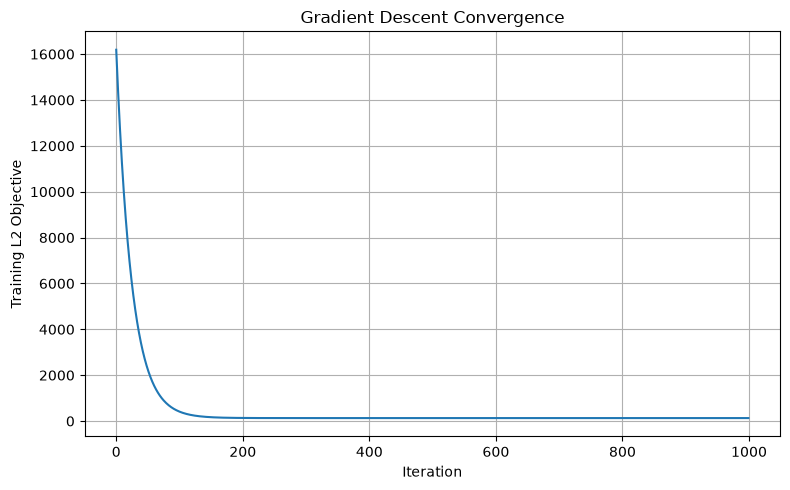

In [12]:

plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Iteration")
plt.ylabel("Training L2 Objective")
plt.title("Gradient Descent Convergence")
plt.grid(True)
plt.tight_layout()
plt.show()


12. Evaluate Model on Test Set :
Compute final performance metrics (MSE, RMSE, MAE, and NRMSE) on the unseen test set to evaluate true generalization capability.

In [14]:

# Final predictions on the held-out test data
y_test_pred = Prediction(X_test, w_final)

# Test metrics
test_l2 = L2_Loss(X_test, y_test, w_final, lambda_)
test_mse = MSE_Loss(y_test, y_test_pred)
test_mae = MAE_Loss(y_test, y_test_pred)
test_rmse = RMSE_Loss(y_test, y_test_pred)
test_nrmse = NRMSE(y_test, y_test_pred)


test_results = pd.DataFrame({
    "Metric": [
        "L2 Objective",
        "MSE",
        "MAE",
        "RMSE",
        "NRMSE"
    ],
    "Test Value": [
        test_l2,
        test_mse,
        test_mae,
        test_rmse,
        test_nrmse
    ]
})

print("FINAL TEST RESULTS")
print("Test samples:", len(y_test))
display(test_results)


FINAL TEST RESULTS
Test samples: 400


,Metric,Test Value
0,L2 Objective,148.956944
1,MSE,93.546404
2,MAE,6.525766
3,RMSE,9.671939
4,NRMSE,0.036418


13. Plot Predictions vs Actual Values :
Create a scatter plot comparing actual target values (`Next_Tmax`) against model predictions on the test set to visualize model accuracy.

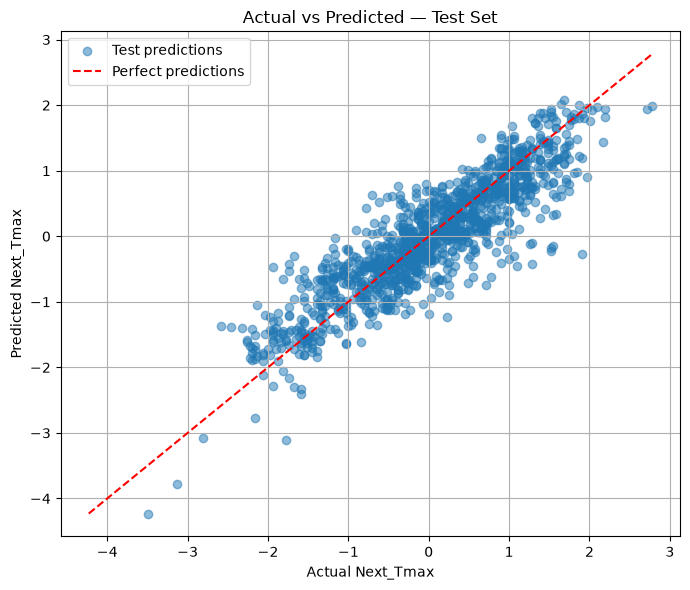

In [13]:
plt.xlabel("Actual Remaining Range")
plt.ylabel("Predicted Remaining Range")
plt.title("Actual vs Predicted — Test Set")

14. Analyze Model Weights :
Inspect the learned model parameters and feature coefficients to determine the relative impact and importance of each predictor variable.

In [26]:
comparison = pd.DataFrame({
    "Actual Remaining Range": y_test.ravel(),
    "Predicted Remaining Range": y_test_pred.ravel()
})

comparison["Absolute Error"] = np.abs(
    comparison["Actual Remaining Range"] - comparison["Predicted Remaining Range"]
)

display(comparison.head(15))

ValueError: All arrays must be of the same length